# Proposed ALM research framework

This notebook is the executable research entry point for audibility-aware data policies, mask-supervised class-query attention, and audibility/cost-aware objectives. It uses the authenticated `mad_source_disjoint_v1` train/validation dataset and never opens the official test set.

Training is deliberately gated by `RUN_TRAINING = False`; changing that value is the explicit user action that starts a configured run.

## 1 — Research objective

The study asks whether three controlled additions improve multilabel military-audio recognition: (A) labels and loss weights informed by measured source audibility, (B) class-query pooling with auxiliary supervision from synthetic source masks, and (C) asymmetric/confusion-aware objectives. Ordinary waveform mixing and union labels remain the B0 control.

The CNN backbone, gated time-frequency fusion, Transformer, independent sigmoid logits, ASL, threshold calibration, and ideal ratio masks are established techniques or engineering choices. The audibility-policy comparison and the use of source-contribution masks to supervise class-query maps are proposed extensions for this repository; they are hypotheses, not established novelty claims.

Research questions: (1) how often is a present source below a measurable audibility threshold? (2) do spatial class queries learn class-specific evidence? (3) does audibility conditioning improve rare/difficult-source recall without suppressing learnable positives? (4) do ASL or training-derived co-occurrence weights address observed errors?

The notebook reports validation evidence only. It does not claim improvement, significance, perceptual source separation, or novelty until compatible ablation runs have completed.

## 2 — Environment and reproducibility

In [1]:
from pathlib import Path
import json, math, platform, sys, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import soundfile as sf
import torch
from torch.utils.data import DataLoader

ROOT = Path.cwd().resolve()
while not (ROOT / 'src').is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
if not (ROOT / 'src').is_dir():
    raise RuntimeError('Could not identify repository root')
sys.path.insert(0 , str(ROOT))
sys.path.insert(0, str(ROOT / 'src'))

from alm.config import load_experiment, resolve_experiment_paths
from alm.data.provenance import CLASS_NAMES
from alm.data.verification import verify_dataset
from alm.data.dataset import MADMixtureDataset
from alm.data.preprocessing import PREPROCESSING
from alm.losses.combined import CombinedLoss
from alm.losses.cost_sensitive import estimate_training_cooccurrence
from alm.models.alm_model import ALMModel
from alm.training.engine import Trainer
from alm.training.metrics import calibrate_thresholds, mask_metrics, multilabel_metrics
from alm.training.reproducibility import environment_record, seed_everything, worker_seed, write_environment

CONFIG_PATH = ROOT / 'configs/experiments/FULL_proposed_alm_source_disjoint_v1.json'
CFG = load_experiment(CONFIG_PATH)
PATHS = resolve_experiment_paths(ROOT, CFG)
seed_everything(CFG['seed'], deterministic=True)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('root:', ROOT)
print('python:', platform.python_version())
print('torch:', torch.__version__, 'cuda:', torch.version.cuda, 'available:', torch.cuda.is_available())
print('gpu:', torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU')
print('device:', DEVICE, 'config:', CFG['run_id'])

root: /home/sharad/Projects/ALM/ALM
python: 3.12.3
torch: 2.14.1+cu132 cuda: 13.2 available: True
gpu: NVIDIA GeForce RTX 2050
device: cuda config: FULL_proposed_alm_seed42


## 3 — Dataset audit

The audit verifies the existing completion certificate, metadata hashes, class order, train/validation provenance disjointness, and generated split counts. It reads raw metadata needed to validate provenance but never loads official-test audio or uses official-test labels.

In [2]:
audit = verify_dataset(ROOT, verify_waveforms=False)
assert audit['complete'] and audit['overlapping_source_count'] == 0
assert audit['overlapping_group_count'] == 0
metadata = pd.read_csv(PATHS['metadata'], dtype=str)
assert list(json.loads((PATHS['manifest'] / 'labels.json').read_text()).values()) == list(CLASS_NAMES)
assert metadata['split'].value_counts().to_dict() == {'train': 5464, 'val': 965}
assert set(metadata['split']) == {'train', 'val'}
labels = np.stack(metadata['label_vector'].map(lambda x: [int(v) for v in x.split(',')]))
print('class order:', list(CLASS_NAMES))
print('split counts:', metadata['split'].value_counts().to_dict())
print('mix counts:\n', pd.crosstab(metadata['split'], metadata['mix_type']))
print('positive counts:\n', pd.DataFrame(labels, columns=CLASS_NAMES).sum())
print('source overlap:', audit['overlapping_source_count'], 'group overlap:', audit['overlapping_group_count'])
print('certificate:', audit['certificate_sha256'])

class order: ['Communication', 'Gunshot', 'Footsteps', 'Shelling', 'Vehicle', 'Helicopter', 'Fighter']
split counts: {'train': 5464, 'val': 965}
mix counts:
 mix_type  2-class  3-class  clean
split                            
train        1912      820   2732
val           338      145    482
positive counts:
 Communication    1433
Gunshot          1677
Footsteps        1436
Shelling         1525
Vehicle          1533
Helicopter       1482
Fighter          1523
dtype: int64
source overlap: 0 group overlap: 0
certificate: 6dd6c70ba738df3bd39a2b9ddcfe8d4a04708efdeed3fc72bb78f0fd2cbf152f


## 4 — Audibility analysis

The existing full-dataset report is reused as a versioned diagnostic, and a small sample is independently reconstructed through the reusable dataset adapter. Source-to-rest SNR uses the rendered source contribution and `x - s_c`; mask share is a power-mask statistic, not perceptual audibility.

records: 10609 finite SNR: 7395
fraction below -15.0 dB: 0.11311150909605053


,class_name,mix_type,records,snr_median_db,snr_q25_db,snr_q75_db,mask_share_mean,below_threshold_fraction
0,Communication,2-class,625,-4.924188,-13.050310,4.208726,0.445103,0.201600
1,Communication,3-class,425,-9.446585,-17.545897,-2.004237,0.257611,0.324706
2,Communication,clean,383,NaN,NaN,NaN,1.000000,0.000000
3,Gunshot,2-class,636,2.194772,-5.833598,10.927756,0.617994,0.067610
4,Gunshot,3-class,419,-3.877424,-10.403705,2.648974,0.451566,0.116945
5,Gunshot,clean,622,NaN,NaN,NaN,1.000000,0.000000
6,Footsteps,2-class,614,-14.102031,-23.264919,-6.137760,0.465733,0.478827
7,Footsteps,3-class,415,-19.232920,-28.222323,-11.123015,0.275918,0.660241
8,Footsteps,clean,407,NaN,NaN,NaN,1.000000,0.000000
9,Shelling,2-class,674,3.393046,-4.184646,12.476151,0.488128,0.050445


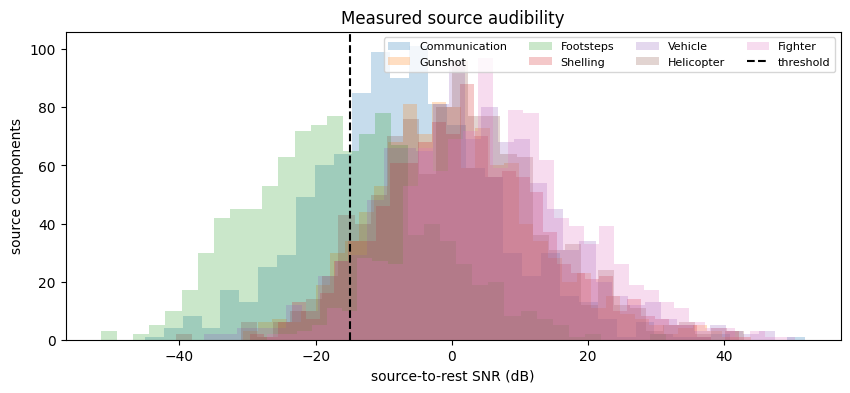

In [3]:
audibility_dir = ROOT / 'research/audibility/mad_source_disjoint_v1'
records = pd.read_csv(audibility_dir / 'audibility_records.csv')
summary = pd.read_csv(audibility_dir / 'audibility_summary.csv')
assert {'snr_db', 'mask_share', 'class_name', 'mix_type'} <= set(records.columns)
threshold = float(CFG['audibility']['threshold_db'])
finite = records[np.isfinite(records['snr_db'])]
print('records:', len(records), 'finite SNR:', len(finite))
print('fraction below', threshold, 'dB:', float((finite['snr_db'] < threshold).sum() / len(records)))
quantiles = (finite.groupby(['class_name', 'mix_type'])['snr_db'].quantile([0.25, 0.75]).unstack().rename(columns={0.25: 'snr_q25_db', 0.75: 'snr_q75_db'}).reset_index())
summary_view = summary[['class_name', 'mix_type', 'records', 'snr_median_db', 'mask_share_mean', 'below_threshold_fraction']].merge(quantiles, on=['class_name', 'mix_type'], how='left')
display(summary_view[['class_name', 'mix_type', 'records', 'snr_median_db', 'snr_q25_db', 'snr_q75_db', 'mask_share_mean', 'below_threshold_fraction']])
fig, ax = plt.subplots(figsize=(10, 4))
for name in CLASS_NAMES:
    values = finite.loc[finite['class_name'] == name, 'snr_db']
    ax.hist(values, bins=35, alpha=0.25, label=name)
ax.axvline(threshold, color='black', linestyle='--', label='threshold')
ax.set(xlabel='source-to-rest SNR (dB)', ylabel='source components', title='Measured source audibility')
ax.legend(ncol=4, fontsize=8); plt.show()

## 5 — Preprocessing and mask verification

{'mel': (1, 128, 313), 'target': (7,), 'union_target': (7,), 'audibility_db': (7,), 'mask_target': (7, 128, 313), 'class_valid': (7,), 'valid_mask': (128, 313), 'id': '2733', 'file': 'mad_ml_002733.wav', 'mix_type': '2-class'}
audibility dB: tensor([    -inf,     -inf,     -inf,     -inf, -12.3536,     -inf,  15.9386])


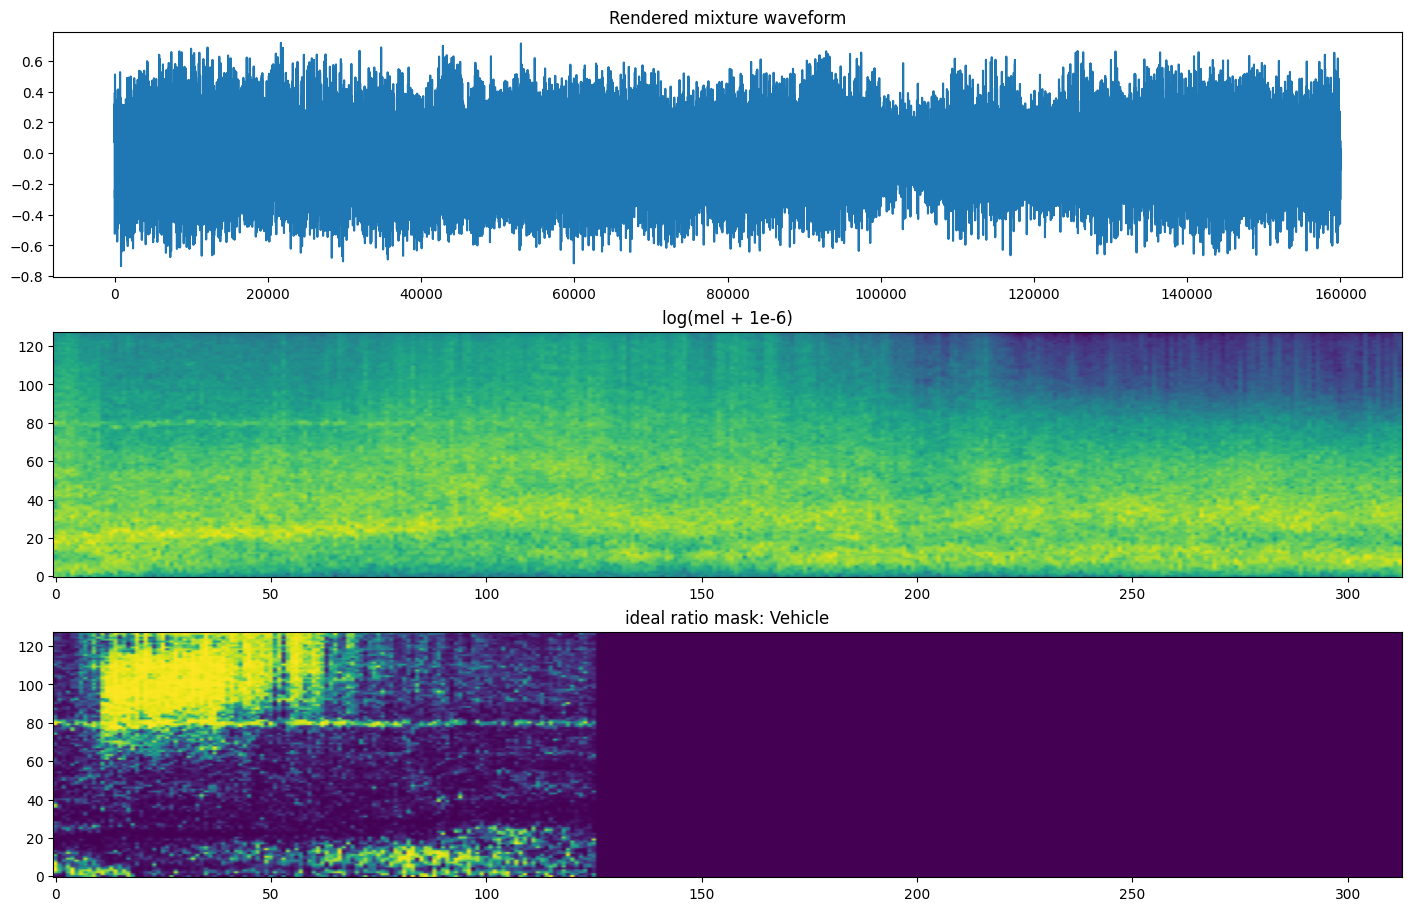

In [4]:
aux_kwargs = dict(metadata_path=PATHS['metadata'], audio_dir=PATHS['audio'],
                  preprocessing=CFG['preprocessing'],
                  source_metadata_path=PATHS['source_metadata'],
                  mixture_manifest_path=PATHS['manifest'] / 'mixture_manifest.csv',
                  source_manifest_path=PATHS['manifest'] / 'source_splits.csv',
                  source_audio_dir=PATHS['source_audio'])
aux_dataset = MADMixtureDataset(**aux_kwargs, split='train', return_aux_targets=True)
sample_index = next(i for i, row in enumerate(aux_dataset.rows) if row['mix_type'] == '2-class')
sample = aux_dataset[sample_index]
assert tuple(sample['mel'].shape) == (1, 128, 313)
assert sample['mask_target'].shape == (7, 128, 313)
assert torch.isfinite(sample['mel']).all() and torch.isfinite(sample['mask_target']).all()
print({key: tuple(value.shape) if hasattr(value, 'shape') else value for key, value in sample.items()})
print('audibility dB:', sample['audibility_db'])

waveform, sr = sf.read(PATHS['audio'] / sample['file'], dtype='float32')
fig, axes = plt.subplots(3, 1, figsize=(14, 9), constrained_layout=True)
axes[0].plot(waveform); axes[0].set_title('Rendered mixture waveform')
axes[1].imshow(sample['mel'][0], origin='lower', aspect='auto'); axes[1].set_title('log(mel + 1e-6)')
class_to_plot = int(sample['class_valid'].nonzero()[0][0])
axes[2].imshow(sample['mask_target'][class_to_plot], origin='lower', aspect='auto', vmin=0, vmax=1)
axes[2].set_title(f'ideal ratio mask: {CLASS_NAMES[class_to_plot]}')
plt.show()

## 6 — Architecture

The model keeps the existing CNN → optional fusion → temporal Transformer path. With queries enabled, local CNN cells are projected to the Transformer dimension, receive the corresponding temporal context, and are queried by seven learned class vectors. The public logits-only forward remains `(B, 7)`; auxiliary mode returns `(B, 7, 8, 78)` attention maps.

In [5]:
model_cfg = CFG['model']
model = ALMModel(**{key: model_cfg[key] for key in ('embed_dim', 'num_heads', 'num_layers', 'ff_dim', 'dropout', 'max_time_frames')},
                 use_fusion=model_cfg['use_fusion'], use_class_queries=model_cfg['use_class_queries'], use_mask_supervision=model_cfg['use_mask_supervision']).to(DEVICE)
model.eval()
with torch.no_grad():
    logits = model(sample['mel'].unsqueeze(0).to(DEVICE))
    auxiliary = model(sample['mel'].unsqueeze(0).to(DEVICE), return_aux=True)
assert tuple(logits.shape) == (1, 7)
assert tuple(auxiliary['attention'].shape) == (1, 7, 8, 78)
print(model)
print('logits:', tuple(logits.shape), 'attention:', tuple(auxiliary['attention'].shape))
print('parameters:', sum(p.numel() for p in model.parameters() if p.requires_grad))

/home/sharad/Projects/ALM/ALM/utils/enhanced_alm_mad_encoder.py:220: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.transformer = nn.TransformerEncoder(encoder_layer, num_layers=num_layers)


ALMModel(
  (backbone): Sequential(
    (0): ConvBlock(
      (conv1): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (conv2): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (pool): MaxPool2d(kernel_size=(2, 2), stride=(2, 2), padding=0, dilation=1, ceil_mode=False)
      (dropout): Dropout2d(p=0.1, inplace=False)
    )
    (1): ConvBlock(
      (conv1): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, 

## 7 — Loss verification

BCE uses stable positive and negative softplus terms. ASL uses separate focal terms and clipped negatives. Audibility weighting applies only to the positive term and has a nonzero floor. Mask supervision is cross entropy between the normalised target ratio-mask distribution and the class-query attention distribution, excluding absent classes and invalid cells.

In [6]:
toy_logits = torch.tensor([[0.0, 2.0, -2.0, 0.5, -0.5, 1.0, -1.0]], requires_grad=True)
toy_targets = torch.tensor([[1., 1., 0., 0., 1., 0., 0.]])
pos_weight = torch.ones(7)
bce = CombinedLoss(pos_weight=pos_weight)
asl = CombinedLoss(pos_weight=pos_weight, use_asymmetric_loss=True)
aud = CombinedLoss(pos_weight=pos_weight, use_audibility_loss=True)
attention = torch.full((1, 7, 8, 78), 1.0 / (8 * 78))
mask_target = torch.zeros_like(attention); mask_target[0, 0, 2:4, 10:20] = 1
full_loss = CombinedLoss(pos_weight=pos_weight, use_asymmetric_loss=True, use_audibility_loss=True, lambda_mask=0.25)
aud_db = torch.tensor([[0., -20., float('-inf'), float('-inf'), -5., float('-inf'), float('-inf')]])
print('BCE:', float(bce(toy_logits, toy_targets)['total']), 'ASL:', float(asl(toy_logits, toy_targets)['total']))
print('audibility-conditioned:', float(aud(toy_logits, toy_targets, audibility_db=aud_db)['total']))
losses = full_loss(toy_logits, toy_targets, audibility_db=aud_db, attention_maps=attention, mask_targets=mask_target, class_valid=torch.tensor([[True, False, False, False, False, False, False]]))
losses['total'].backward()
assert all(torch.isfinite(value).item() for value in losses.values()) and torch.isfinite(toy_logits.grad).all()
print({key: float(value.detach()) for key, value in losses.items()})
print('finite gradients: PASS')

BCE: 0.645954430103302 ASL: 0.30454784631729126
audibility-conditioned: 0.6142606735229492
{'total': 1.8818917274475098, 'classification': 0.27285411953926086, 'mask': 6.436150550842285, 'positive_mean': 0.47159430384635925, 'negative_mean': 0.0}
finite gradients: PASS


/tmp/ipykernel_84335/3092382018.py:11: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /__w/pytorch/pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:820.)
  print('BCE:', float(bce(toy_logits, toy_targets)['total']), 'ASL:', float(asl(toy_logits, toy_targets)['total']))


## 8 — Training

The following cell is the only training entry point. It writes a unique run directory, configuration, environment, checkpoints, history, epoch metrics, and `training.log`. The trainer uses the same logging pattern as the B0 notebook: one file handler, one `tqdm.write` console handler, epoch-labelled progress bars with `leave=False`, `dynamic_ncols=True`, `mininterval=0.5`, running loss/LR postfixes, and one epoch summary log line. For experiments requiring source masks, target reconstruction is precomputed with its own progress bar before model training begins. It does not evaluate the official test set.

In [7]:
RUN_TRAINING = True  # change to True deliberately to start the configured run
RUN_DIR = ROOT / 'runs' / CFG['run_id']
train_rows = metadata[metadata['split'] == 'train']
train_union = torch.tensor(np.stack(train_rows['label_vector'].map(lambda x: [int(v) for v in x.split(',')]).to_numpy()), dtype=torch.float32)
positive = train_union.sum(0)
pos_weight = ((len(train_union) - positive) / positive.clamp_min(1)).clamp(max=CFG['loss']['pos_weight_cap'])
confusion = estimate_training_cooccurrence(train_union) if model_cfg['use_confusion_weights'] else None

needs_aux_targets = any(model_cfg[key] for key in ('use_mask_supervision', 'use_audibility_labels', 'use_audibility_loss'))

def build_dataset(split):
    return MADMixtureDataset(**aux_kwargs, split=split, return_aux_targets=needs_aux_targets,
        label_policy=CFG['audibility']['policy'] if model_cfg['use_audibility_labels'] else 'union',
        audibility_threshold_db=CFG['audibility']['threshold_db'],
        soft_audibility_center_db=CFG['audibility']['center_db'],
        soft_audibility_temperature_db=CFG['audibility']['temperature_db'],
        soft_audibility_floor=CFG['audibility']['soft_floor'],
        cache_dir=(RUN_DIR / 'audibility_cache' / split) if RUN_TRAINING and needs_aux_targets else None)

def start_training():
    if RUN_DIR.exists():
        raise FileExistsError(f'refusing to overwrite {RUN_DIR}')
    RUN_DIR.mkdir(parents=True)
    (RUN_DIR / 'plots').mkdir()
    train_ds, val_ds = build_dataset('train'), build_dataset('val')
    generator = torch.Generator().manual_seed(CFG['seed'])
    train_loader = DataLoader(train_ds, batch_size=CFG['training']['batch_size'], shuffle=True, num_workers=CFG['training']['num_workers'], generator=generator, worker_init_fn=worker_seed, pin_memory=DEVICE.type == 'cuda')
    val_loader = DataLoader(val_ds, batch_size=CFG['training']['batch_size'] * 2, shuffle=False, num_workers=CFG['training']['num_workers'], worker_init_fn=worker_seed, pin_memory=DEVICE.type == 'cuda')
    loss_fn = CombinedLoss(num_classes=7, pos_weight=pos_weight, use_asymmetric_loss=model_cfg['use_asymmetric_loss'], use_audibility_loss=model_cfg['use_audibility_loss'], audibility_floor=CFG['loss']['audibility_floor'], confusion_matrix=confusion, confusion_strength=CFG['loss'].get('confusion_strength', 1.0), lambda_mask=CFG['loss']['lambda_mask'])
    optimizer = torch.optim.AdamW(model.parameters(), lr=CFG['training']['lr'], weight_decay=CFG['training']['weight_decay'])
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=CFG['training']['epochs'], eta_min=CFG['training']['eta_min'])
    with (RUN_DIR / 'config.json').open('x') as handle: json.dump(CFG, handle, indent=2)
    write_environment(RUN_DIR / 'environment.json', ROOT)
    trainer = Trainer(model, loss_fn, optimizer, device=DEVICE, run_dir=RUN_DIR, scheduler=scheduler, epochs=CFG['training']['epochs'], grad_clip=CFG['training']['grad_clip'], amp=CFG['training']['amp'], checkpoint_metric=CFG['training']['checkpoint_metric'])
    return trainer.fit(train_loader, val_loader)

if RUN_TRAINING:
    training_result = start_training()
    print(training_result['best_epoch'], training_result['best_value'])
else:
    print('Training is gated. Set RUN_TRAINING = True and rerun this cell to start.')

2026-10-12 22:29:01 | INFO | Experiment startup | run_id=FULL_proposed_alm_seed42 | dir=/home/sharad/Projects/ALM/ALM/runs/FULL_proposed_alm_seed42
2026-10-12 22:29:01 | INFO | DataLoaders | train_batches=171 val_batches=16 | amp=True | progress=NotebookTextProgress
2026-10-12 22:29:01 | INFO | Log file: /home/sharad/Projects/ALM/ALM/runs/FULL_proposed_alm_seed42/training.log
2026-10-12 22:29:01 | INFO | Preparing train targets (reusing cached targets where available)


2026-10-12 22:31:12 | INFO | Preparing validation targets (reusing cached targets where available)


2026-10-12 22:31:36 | INFO | TRAINING START | epochs=60 | device=cuda


2026-10-12 22:32:50 | INFO | Best checkpoint updated | epoch=1 | val_mAP=0.2726 | /home/sharad/Projects/ALM/ALM/runs/FULL_proposed_alm_seed42/best_model.pt
2026-10-12 22:32:50 | INFO | Epoch 1/60 | train_loss=1.6842 | val_loss=1.6109 | val_mAP=0.2726 | macro_F1=0.3815 micro_F1=0.3818 | lr=3.000e-04 | time=74.3s | best_updated=True


2026-10-12 22:34:05 | INFO | Best checkpoint updated | epoch=2 | val_mAP=0.5300 | /home/sharad/Projects/ALM/ALM/runs/FULL_proposed_alm_seed42/best_model.pt
2026-10-12 22:34:05 | INFO | Epoch 2/60 | train_loss=1.6025 | val_loss=1.5777 | val_mAP=0.5300 | macro_F1=0.5048 micro_F1=0.5149 | lr=2.998e-04 | time=74.2s | best_updated=True


...

2026-10-12 23:40:38 | INFO | Epoch 56/60 | train_loss=1.3993 | val_loss=1.5369 | val_mAP=0.8425 | macro_F1=0.7791 micro_F1=0.7855 | lr=5.111e-06 | time=73.3s | best_updated=False


2026-10-12 23:41:52 | INFO | Epoch 57/60 | train_loss=1.3993 | val_loss=1.5370 | val_mAP=0.8426 | macro_F1=0.7770 micro_F1=0.7837 | lr=3.278e-06 | time=73.5s | best_updated=False


2026-10-12 23:43:06 | INFO | Epoch 58/60 | train_loss=1.3997 | val_loss=1.5368 | val_mAP=0.8419 | macro_F1=0.7787 micro_F1=0.7851 | lr=1.847e-06 | time=73.4s | best_updated=False


2026-10-12 23:44:20 | INFO | Epoch 59/60 | train_loss=1.3994 | val_loss=1.5368 | val_mAP=0.8415 | macro_F1=0.7794 micro_F1=0.7861 | lr=8.217e-07 | time=74.1s | best_updated=False


2026-10-12 23:45:34 | INFO | Epoch 60/60 | train_loss=1.3992 | val_loss=1.5359 | val_mAP=0.8437 | macro_F1=0.7800 micro_F1=0.7861 | lr=2.056e-07 | time=73.8s | best_updated=False
2026-10-12 23:45:34 | INFO | TRAINING COMPLETE | epochs=60 | best_epoch=18 | best_val_mAP=0.8626 | total_time=4592.6s
18 0.8625985128995498


## 9 — Evaluation and analysis

This cell evaluates validation predictions from the selected checkpoint, calibrates thresholds on validation only, reports uncalibrated and calibrated metrics, and saves class metrics/thresholds/attention figures. It can also compare the recorded B0 validation mAP when the existing B0 artifact is present.

uncalibrated: {'mAP': 0.8638622432883185, 'macro_f1': 0.7592925965340463, 'micro_f1': 0.7622337363270005, 'hamming_loss': 0.12227979274611399}
calibrated: {'mAP': 0.8638622432883185, 'macro_f1': 0.7954129641452375, 'micro_f1': 0.7968901846452867, 'hamming_loss': 0.092820133234641}
mask metrics: {'valid_class_maps': 1593, 'mean_target_to_attention_kl': 5.727880002539998}


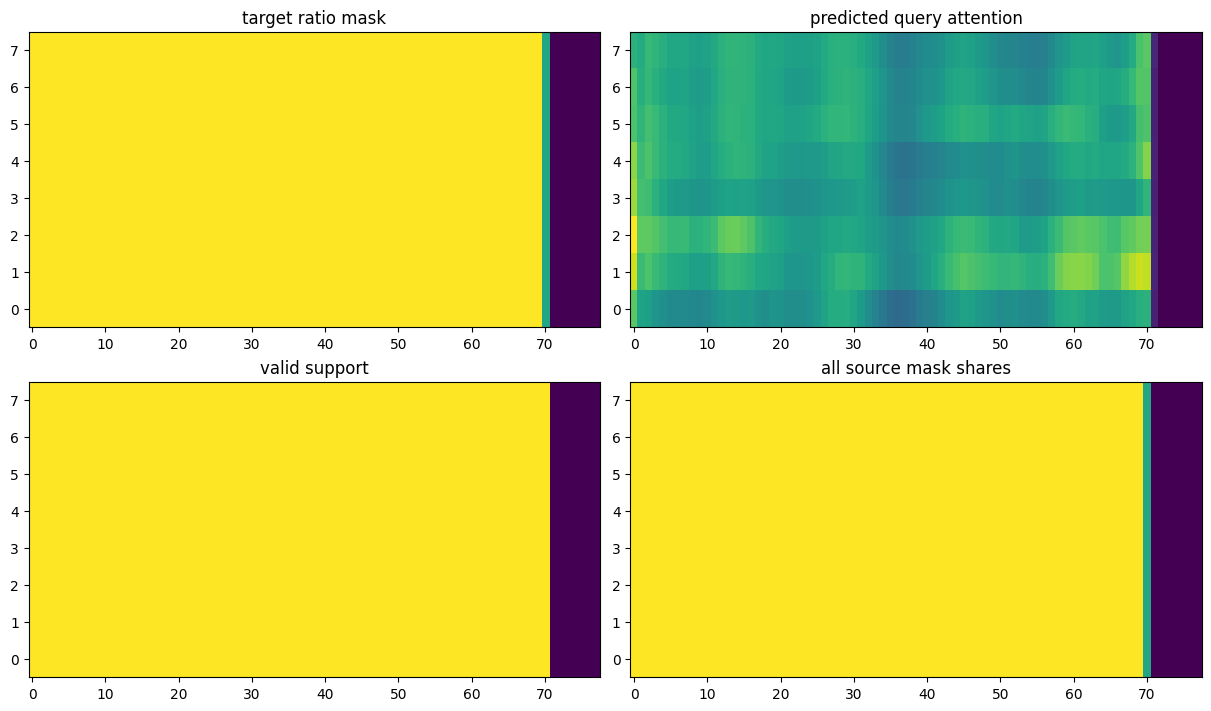

In [8]:
def collect_validation(model, loader):
    model.eval(); targets, scores, attentions, masks, valid, class_valid = [], [], [], [], [], []
    with torch.no_grad():
        for batch in loader:
            output = model(batch['mel'].to(DEVICE), return_aux=True)
            targets.append(batch.get('union_target', batch['target']).numpy()); scores.append(torch.sigmoid(output['logits']).cpu().numpy())
            if 'attention' in output:
                attentions.append(output['attention'].cpu().numpy())
                masks.append(torch.nn.functional.interpolate(batch['mask_target'].float(), size=output['attention'].shape[-2:], mode='bilinear', align_corners=False).numpy())
                valid.append(torch.nn.functional.interpolate(batch['valid_mask'][:, None].float(), size=output['attention'].shape[-2:], mode='nearest')[:, 0].numpy())
                class_valid.append(batch['class_valid'].numpy())
    return np.concatenate(targets), np.concatenate(scores), (np.concatenate(attentions) if attentions else None), (np.concatenate(masks) if masks else None), (np.concatenate(valid) if valid else None), (np.concatenate(class_valid) if class_valid else None)

if RUN_TRAINING and RUN_DIR.exists():
    eval_ds = build_dataset('val')
    eval_loader = DataLoader(eval_ds, batch_size=CFG['training']['batch_size'] * 2, shuffle=False)
    checkpoint = torch.load(RUN_DIR / 'best_model.pt', map_location=DEVICE, weights_only=False)
    model.load_state_dict(checkpoint['model_state'])
    y_true, y_score, attention_maps, mask_targets, valid_maps, class_valid = collect_validation(model, eval_loader)
    uncalibrated = multilabel_metrics(y_true, y_score)
    calibration = calibrate_thresholds(y_true, y_score, strategy='per_class_f1')
    calibrated = multilabel_metrics(y_true, y_score, thresholds=calibration['thresholds'])
    print('uncalibrated:', {k: uncalibrated[k] for k in ('mAP', 'macro_f1', 'micro_f1', 'hamming_loss')})
    print('calibrated:', {k: calibrated[k] for k in ('mAP', 'macro_f1', 'micro_f1', 'hamming_loss')})
    pd.DataFrame.from_dict(calibrated['per_class'], orient='index').to_csv(RUN_DIR / 'class_metrics.csv')
    (RUN_DIR / 'thresholds.json').write_text(json.dumps(calibration, indent=2))
    if attention_maps is not None:
        mask_result = mask_metrics(attention_maps, mask_targets, class_valid=class_valid)
        print('mask metrics:', mask_result)
        (RUN_DIR / 'attention_visualizations').mkdir(exist_ok=True)
        fig, axes = plt.subplots(2, 2, figsize=(12, 7), constrained_layout=True)
        class_id = int(np.flatnonzero(class_valid[0])[0])
        axes[0, 0].imshow(mask_targets[0, class_id], origin='lower', aspect='auto'); axes[0, 0].set_title('target ratio mask')
        axes[0, 1].imshow(attention_maps[0, class_id], origin='lower', aspect='auto'); axes[0, 1].set_title('predicted query attention')
        axes[1, 0].imshow(valid_maps[0], origin='lower', aspect='auto'); axes[1, 0].set_title('valid support')
        axes[1, 1].imshow(mask_targets[0].sum(0), origin='lower', aspect='auto'); axes[1, 1].set_title('all source mask shares')
        fig.savefig(RUN_DIR / 'attention_visualizations' / 'validation_example.png', dpi=160); plt.show()
else:
    print('No new run selected; evaluation is waiting for an explicit training run.')
    historical = ROOT / 'runs/B0_mad_source_disjoint_v1_seed42/history.json'
    if historical.exists():
        print('recorded compatible B0 best validation mAP:', json.loads(historical.read_text())['best_val_map'])

## 10 — Experiment summary

A completed run should be summarised with its exact configuration, seed, dataset certificate, best validation epoch, calibrated thresholds, and component metrics. The result establishes only validation behavior under the selected source-disjoint protocol. Recommended order: B0 → B1/B2 → B3 → B4 → B5 → B6 → B7 confusion → FULL; run the operational-cost template only after a domain matrix is supplied.

In [9]:
summary = {'run_id': CFG['run_id'], 'config': str(CONFIG_PATH.relative_to(ROOT)), 'seed': CFG['seed'], 'dataset_certificate': str((PATHS['manifest'] / 'COMPLETE.json').relative_to(ROOT)), 'official_test_used': False}
if RUN_DIR.exists() and (RUN_DIR / 'history.json').exists():
    history = json.loads((RUN_DIR / 'history.json').read_text())
    summary.update({'best_epoch': history['best_epoch'], 'best_validation_metric': history['best_value']})
    lines = ['# Experiment summary', '', f"Run: `{CFG['run_id']}`", f"Best epoch: {history['best_epoch']}", f"Best validation {CFG['training']['checkpoint_metric']}: {history['best_value']:.6f}", '', 'Official test used: false', '', 'This is validation evidence under the source-disjoint protocol.']
    (RUN_DIR / 'summary.md').write_text('\n'.join(lines))
print(json.dumps(summary, indent=2))

{
  "run_id": "FULL_proposed_alm_seed42",
  "config": "configs/experiments/FULL_proposed_alm_source_disjoint_v1.json",
  "seed": 42,
  "dataset_certificate": "data/manifests/mad_source_disjoint_v1/COMPLETE.json",
  "official_test_used": false,
  "best_epoch": 18,
  "best_validation_metric": 0.8625985128995498
}
